 Phase 1: Setup & Data Acquisition

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
sns.set_theme(style="whitegrid")

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Phase 02: Data Cleaning (The "Wrangling" Part)

1. Fix Data Types: The TotalCharges column often looks like numbers but is actually "text" (object) because of some empty spaces. Fix it with:


In [3]:
#Convert TotalCharges to numeric, turning errors (spaces) into NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

#Fill the few missing values with the median
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())


2. Verify: Run df.info() to make sure everything is now a number or a category.

Phase 03: Answering the Business Questions



Question 1: Overall Attrition Baseline

Goal: What percentage of customers are leaving?

/tmp/ipykernel_616/2345232768.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette='viridis')


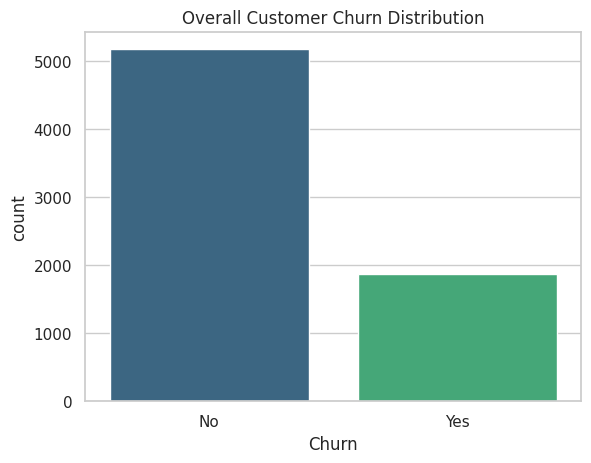

Baseline Churn Rate: 26.54%


In [5]:
churn_rate = df['Churn'].value_counts(normalize=True) * 100
sns.countplot(data=df, x='Churn', palette='viridis')
plt.title('Overall Customer Churn Distribution')
plt.show()
print(f"Baseline Churn Rate: {churn_rate['Yes']:.2f}%")

Business Insight: The overall churn rate is approximately 26.5%. This means more than one-fourth of the customer base has left the company. This baseline provides a critical KPI (Key Performance Indicator) that the company must aim to reduce through better retention strategies.

Question 2: Contract Impact

 Goal: Do long-term contracts stop people from leaving?

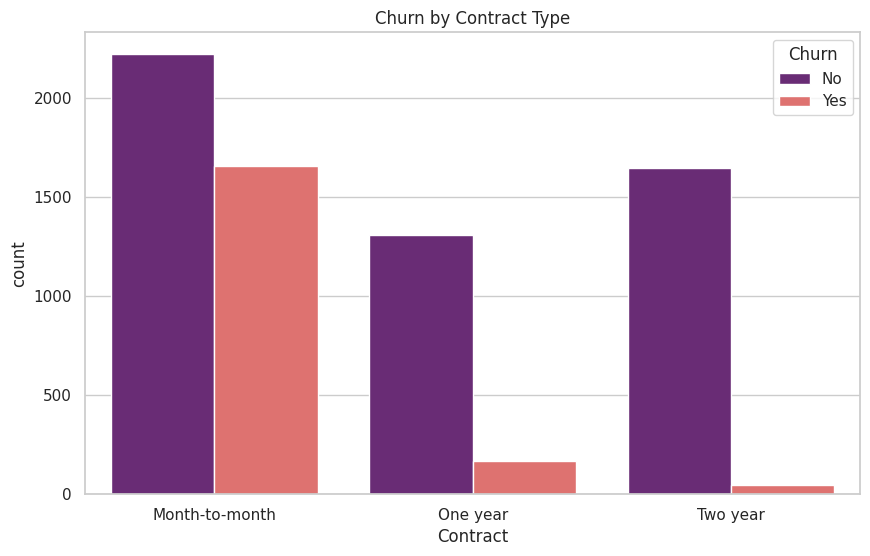

In [4]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Contract', hue='Churn', palette='magma')
plt.title('Churn by Contract Type')
plt.show()

Business Insight: There is a massive difference in churn based on contract type. Customers with "Month-to-Month" contracts show the highest attrition, while those with "One Year" or "Two Year" contracts are very stable. This indicates that long-term commitment is a strong predictor of loyalty, and the company should offer incentives to move month-to-month users into longer contracts.

Question 3: Billing & Payment Factors

Goal: Does the way they pay affect whether they leave?

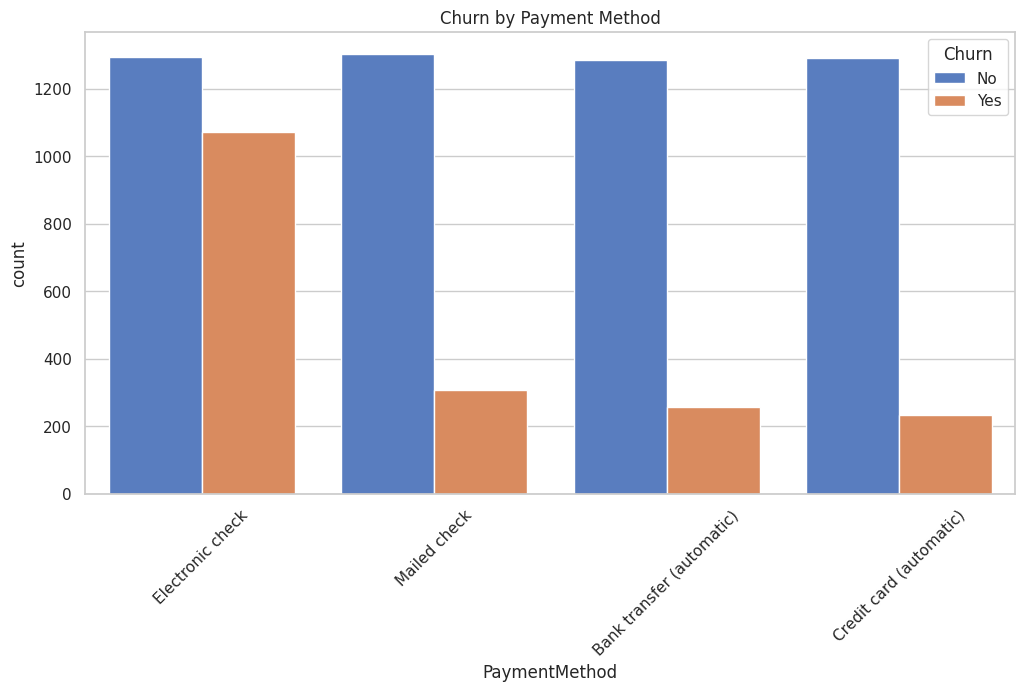

In [6]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='PaymentMethod', hue='Churn', palette='muted')
plt.xticks(rotation=45)
plt.title('Churn by Payment Method')
plt.show()

Business Insight: The payment method "Electronic Check" is associated with a significantly higher number of churning customers compared to Credit Card or Bank Transfer payments. This suggests there may be a technical issue, a lack of trust, or a poor user experience associated with the electronic check process that is driving customers away.